##Dataset

In [2]:
# Importar fonte de dados do Kaggle
import kagglehub
path = kagglehub.dataset_download('expeditojunior/enade20082018')

print('Dataset importado.')

# Importar pacotes
import numpy as np
import pandas as pd
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

Using Colab cache for faster access to the 'enade20082018' dataset.
Dataset importado.
/kaggle/input/enade20082018/enade_2008_2018.rds


In [3]:
# Importa as bibliotecas necessárias para conversão R-Python
import os
import pandas as pd
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri

# Ativa a conversão automática de objetos R para Pandas
pandas2ri.activate()

# Localiza o arquivo .rds baixado pelo kagglehub no diretório do cache
# 'path' foi definido na primeira célula após o download do Kaggle
try:
    # Procura por qualquer arquivo .rds dentro do diretório baixado
    arquivos_rds = [os.path.join(raiz, arq) for raiz, _, arqs in os.walk(path) for arq in arqs if arq.endswith('.rds')]
    if arquivos_rds:
        caminho_arquivo = arquivos_rds[0]
        print(f"Arquivo encontrado em: {caminho_arquivo}")
    else:
        raise FileNotFoundError("Nenhum arquivo .rds encontrado no diretório de download.")
except NameError:
    # Caso a variável 'path' não esteja definida, usa um caminho padrão do cache do kagglehub
    caminho_arquivo = '/root/.cache/kagglehub/datasets/expeditojunior/enade20082018/2/enade_2008_2018.rds'
    print(f"Variável 'path' não encontrada. Tentando caminho padrão: {caminho_arquivo}")

# Carrega os dados utilizando o motor nativo do R
print("Carregando os dados via rpy2 (R)...")
readRDS = robjects.r['readRDS']
df_r = readRDS(caminho_arquivo)

# Converte o objeto do R em um DataFrame do Pandas
df = pandas2ri.rpy2py(df_r)

# Exibe as dimensões do dataset
print(f"\nDimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

Arquivo encontrado em: /kaggle/input/enade20082018/enade_2008_2018.rds
Carregando os dados via rpy2 (R)...

Dimensões do dataset: 3712412 linhas e 20 colunas



In [4]:
# Visualizar dataframe
print(df.head())
print(df.info())
print(df.describe())

   NU_ANO  NU_IDADE  TP_SEXO  ANO_FIM_EM  ANO_IN_GRAD  QE_I13  QE_I14  NT_FG  \
1       1        21        1        2005            0       3       3    7.5   
2       1        23        2        2000         2003       3       3    7.5   
3       1        33        2        2000         2002       7       8   22.5   
4       1        36        2        1995         1996       3       3   31.5   
7       1        45        2        1995         2001       3       3   54.0   

       NT_CE     NT_GER MUNICIPIO  UF       LONG        LAT         ALT  \
1  18.900000  16.100000    CUIABÁ  11 -56.073252 -15.569989  242.927031   
2  22.000000  18.400000    CUIABÁ  11 -56.073252 -15.569989  242.927031   
3   9.400000  12.700000    CUIABÁ  11 -56.073252 -15.569989  242.927031   
4  12.600000  17.299999    CUIABÁ  11 -56.073252 -15.569989  242.927031   
7  34.599998  39.500000    CUIABÁ  11 -56.073252 -15.569989  242.927031   

           CATEGAD       GRUPO   ORGANIZACAO  REGIAO_CURSO       CUR

Text(0.5, 1.0, 'Matriz de Correlação')

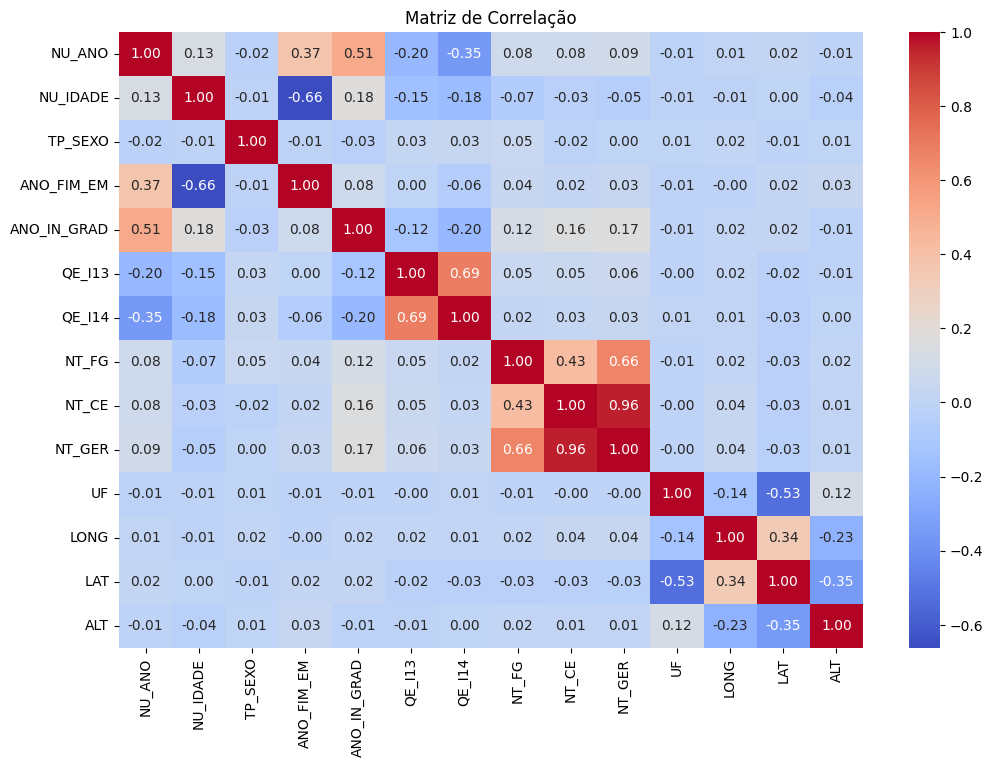

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Matriz de correlação
numeric_df = df.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_df.corr()

# Plotar matriz de correlação
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlação')

##Aprendizado supervisionado

In [ ]:
# =========================
# PREPARAÇÃO DOS DADOS
# =========================

print(df.columns)

target = 'NT_GER'

X = df.drop(columns=[target])
y = df[target]

X = pd.get_dummies(X, drop_first=True)

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Index(['NU_ANO', 'NU_IDADE', 'TP_SEXO', 'ANO_FIM_EM', 'ANO_IN_GRAD', 'QE_I13',
       'QE_I14', 'NT_FG', 'NT_CE', 'NT_GER', 'MUNICIPIO', 'UF', 'LONG', 'LAT',
       'ALT', 'CATEGAD', 'GRUPO', 'ORGANIZACAO', 'REGIAO_CURSO', 'CURSO'],
      dtype='object')


In [ ]:
# =========================
# MODELOS DE CLASSIFICAÇÃO
# =========================

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

# Testar com diferentes valores de test_size e random_state
test_sizes = [0.2, 0.25, 0.3, 0.5]
random_states = [0, 1, 2, 15, 33]

models = {
    "SVM": SVC(),
    "GaussianNB": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "Perceptron_Simples": Perceptron()
}

# Variar o número de camadas e neurônios no MLP
mlp_configurations = [
    {"name": "MLP_10_5", "hidden_layer_sizes": (10, 5)},
    {"name": "MLP_20", "hidden_layer_sizes": (20,)},
    {"name": "MLP_50_25_10", "hidden_layer_sizes": (50, 25, 10)}
]

for config in mlp_configurations:
    models[f"MLP_{config['name']}"] = MLPClassifier(hidden_layer_sizes=config['hidden_layer_sizes'], max_iter=1000)

results = []

In [ ]:
# =========================
# TREINAMENTO E AVALIAÇÃO
# =========================

for test_size in test_sizes:
    for random_state in random_states:

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state
        )

        for name, model in models.items():

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            acc = accuracy_score(y_test, y_pred)
            cm = confusion_matrix(y_test, y_pred)

            results.append({
                "Modelo": name,
                "Test Size": test_size,
                "Random State": random_state,
                "Acuracia": acc
            })

            print(f"\nModelo: {name}")
            print(f"Test size: {test_size} | Random state: {random_state}")
            print(f"Acurácia: {acc:.4f}")
            print("Matriz de Confusão:")
            print(cm)


Modelo: SVM
Test size: 0.2 | Random state: 0
Acurácia: 0.7150
Matriz de Confusão:
[[77 28]
 [29 66]]

Modelo: GaussianNB
Test size: 0.2 | Random state: 0
Acurácia: 0.7600
Matriz de Confusão:
[[87 18]
 [30 65]]

Modelo: KNN
Test size: 0.2 | Random state: 0
Acurácia: 0.7250
Matriz de Confusão:
[[65 40]
 [15 80]]

Modelo: Perceptron_Simples
Test size: 0.2 | Random state: 0
Acurácia: 0.5350
Matriz de Confusão:
[[100   5]
 [ 88   7]]

Modelo: MLP_MLP_10_5
Test size: 0.2 | Random state: 0
Acurácia: 0.7500
Matriz de Confusão:
[[73 32]
 [18 77]]

Modelo: MLP_MLP_20
Test size: 0.2 | Random state: 0
Acurácia: 0.7250
Matriz de Confusão:
[[86 19]
 [36 59]]

Modelo: MLP_MLP_50_25_10
Test size: 0.2 | Random state: 0
Acurácia: 0.7300
Matriz de Confusão:
[[79 26]
 [28 67]]

Modelo: SVM
Test size: 0.2 | Random state: 1
Acurácia: 0.6550
Matriz de Confusão:
[[66 45]
 [24 65]]

Modelo: GaussianNB
Test size: 0.2 | Random state: 1
Acurácia: 0.7100
Matriz de Confusão:
[[80 31]
 [27 62]]

Modelo: KNN
Test si

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(



Modelo: MLP_MLP_10_5
Test size: 0.25 | Random state: 15
Acurácia: 0.7080
Matriz de Confusão:
[[83 49]
 [24 94]]

Modelo: MLP_MLP_20
Test size: 0.25 | Random state: 15
Acurácia: 0.6760
Matriz de Confusão:
[[71 61]
 [20 98]]

Modelo: MLP_MLP_50_25_10
Test size: 0.25 | Random state: 15
Acurácia: 0.7320
Matriz de Confusão:
[[93 39]
 [28 90]]

Modelo: SVM
Test size: 0.25 | Random state: 33
Acurácia: 0.7680
Matriz de Confusão:
[[100  24]
 [ 34  92]]

Modelo: GaussianNB
Test size: 0.25 | Random state: 33
Acurácia: 0.7960
Matriz de Confusão:
[[108  16]
 [ 35  91]]

Modelo: KNN
Test size: 0.25 | Random state: 33
Acurácia: 0.7720
Matriz de Confusão:
[[ 82  42]
 [ 15 111]]

Modelo: Perceptron_Simples
Test size: 0.25 | Random state: 33
Acurácia: 0.5720
Matriz de Confusão:
[[ 42  82]
 [ 25 101]]

Modelo: MLP_MLP_10_5
Test size: 0.25 | Random state: 33
Acurácia: 0.7800
Matriz de Confusão:
[[ 88  36]
 [ 19 107]]

Modelo: MLP_MLP_20
Test size: 0.25 | Random state: 33
Acurácia: 0.7760
Matriz de Confus

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(



Modelo: MLP_MLP_10_5
Test size: 0.5 | Random state: 2
Acurácia: 0.7060
Matriz de Confusão:
[[155  95]
 [ 52 198]]

Modelo: MLP_MLP_20
Test size: 0.5 | Random state: 2
Acurácia: 0.7180
Matriz de Confusão:
[[167  83]
 [ 58 192]]

Modelo: MLP_MLP_50_25_10
Test size: 0.5 | Random state: 2
Acurácia: 0.7000
Matriz de Confusão:
[[175  75]
 [ 75 175]]

Modelo: SVM
Test size: 0.5 | Random state: 15
Acurácia: 0.7060
Matriz de Confusão:
[[175  80]
 [ 67 178]]

Modelo: GaussianNB
Test size: 0.5 | Random state: 15
Acurácia: 0.7380
Matriz de Confusão:
[[193  62]
 [ 69 176]]

Modelo: KNN
Test size: 0.5 | Random state: 15
Acurácia: 0.7100
Matriz de Confusão:
[[159  96]
 [ 49 196]]

Modelo: Perceptron_Simples
Test size: 0.5 | Random state: 15
Acurácia: 0.5640
Matriz de Confusão:
[[113 142]
 [ 76 169]]

Modelo: MLP_MLP_10_5
Test size: 0.5 | Random state: 15
Acurácia: 0.6660
Matriz de Confusão:
[[176  79]
 [ 88 157]]

Modelo: MLP_MLP_20
Test size: 0.5 | Random state: 15
Acurácia: 0.6920
Matriz de Confus

In [ ]:
# =========================
# RESULTADOS
# =========================

import pandas as pd

results_df = pd.DataFrame(results)
results_df.sort_values(by="Acuracia", ascending=False)

,Modelo,Test Size,Random State,Acuracia
64,GaussianNB,0.25,33,0.796000
27,MLP_MLP_50_25_10,0.20,15,0.785000
28,SVM,0.20,33,0.780000
36,GaussianNB,0.25,0,0.780000
99,GaussianNB,0.30,33,0.780000
...,...,...,...,...
101,Perceptron_Simples,0.30,33,0.503333
73,Perceptron_Simples,0.30,0,0.493333
10,Perceptron_Simples,0.20,1,0.490000
80,Perceptron_Simples,0.30,1,0.473333


Com os valores utilizados o melhor resultado foi com o modelo Gaussian Naive Bayes apresentou a melhor acurácia 79,6%, possivelmente porque os atributos do dataset possuem comportamento próximo de uma distribuição gaussiana. O modelo é simples, possui baixa complexidade computacional e costuma funcionar bem em datasets tabulares com poucos atributos.

##Aprendizado Não supervisionado

O PCA não foi aplicado porque o dataset utilizado possui apenas 8 variáveis preditoras, caracterizando um conjunto de baixa dimensionalidade.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Preparar os dados para o K-Means
# Excluir a coluna 'Outcome' para o clustering, pois é o target que queremos comparar
X_kmeans = df_balanceado.drop('Outcome', axis=1)

# Escalonar os dados para o K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)

# Aplicar o K-Means com 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Obter os rótulos dos clusters
clusters = kmeans.labels_

# Adicionar os rótulos dos clusters ao dataframe balanceado para comparação
df_balanceado['Cluster'] = clusters

# Contar os pontos em cada cluster
print("Distribuição dos clusters K-Means:")
print(pd.Series(clusters).value_counts())

# Comparar os clusters com a coluna 'Outcome'
print("\nComparação entre os rótulos do K-Means e a coluna 'Outcome':")
print(pd.crosstab(df_balanceado['Outcome'], df_balanceado['Cluster']))

# Mapear os clusters para o 'Outcome'
mapping = {}
crosstab_df = pd.crosstab(df_balanceado['Outcome'], df_balanceado['Cluster'])

if crosstab_df.loc[0, 0] > crosstab_df.loc[1, 0]: # Se Outcome 0 é mais prevalente no Cluster 0
    mapping[0] = 0
    mapping[1] = 1 # O outro cluster deve ser o Outcome 1
else:
    mapping[0] = 1
    mapping[1] = 0 # O outro cluster deve ser o Outcome 0

# Aplicar o mapeamento para obter os rótulos de cluster 'alinhados'
df_balanceado['Aligned_Cluster'] = df_balanceado['Cluster'].map(mapping)

# Calcular a acurácia do agrupamento em relação ao Outcome
accuracy_kmeans = (df_balanceado['Outcome'] == df_balanceado['Aligned_Cluster']).mean()
print(f"\nAcurácia do K-Means: {accuracy_kmeans:.1%}")

Distribuição dos clusters K-Means:
1    589
0    411
Name: count, dtype: int64

Comparação entre os rótulos do K-Means e a coluna 'Outcome':
Cluster    0    1
Outcome          
0        125  375
1        286  214

Acurácia do K-Means: 66.1%


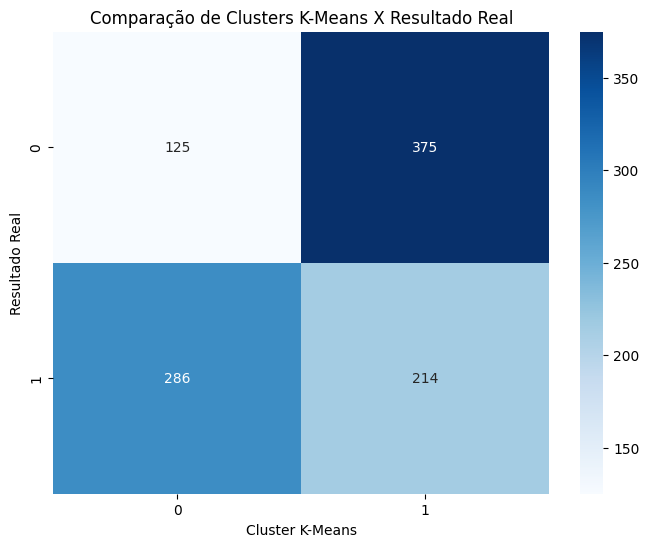

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


# Criar um heatmap da tabela de contingência
plt.figure(figsize=(8, 6))
sns.heatmap(crosstab_df, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Comparação de Clusters K-Means X Resultado Real')
plt.xlabel('Cluster K-Means')
plt.ylabel('Resultado Real')
plt.show()

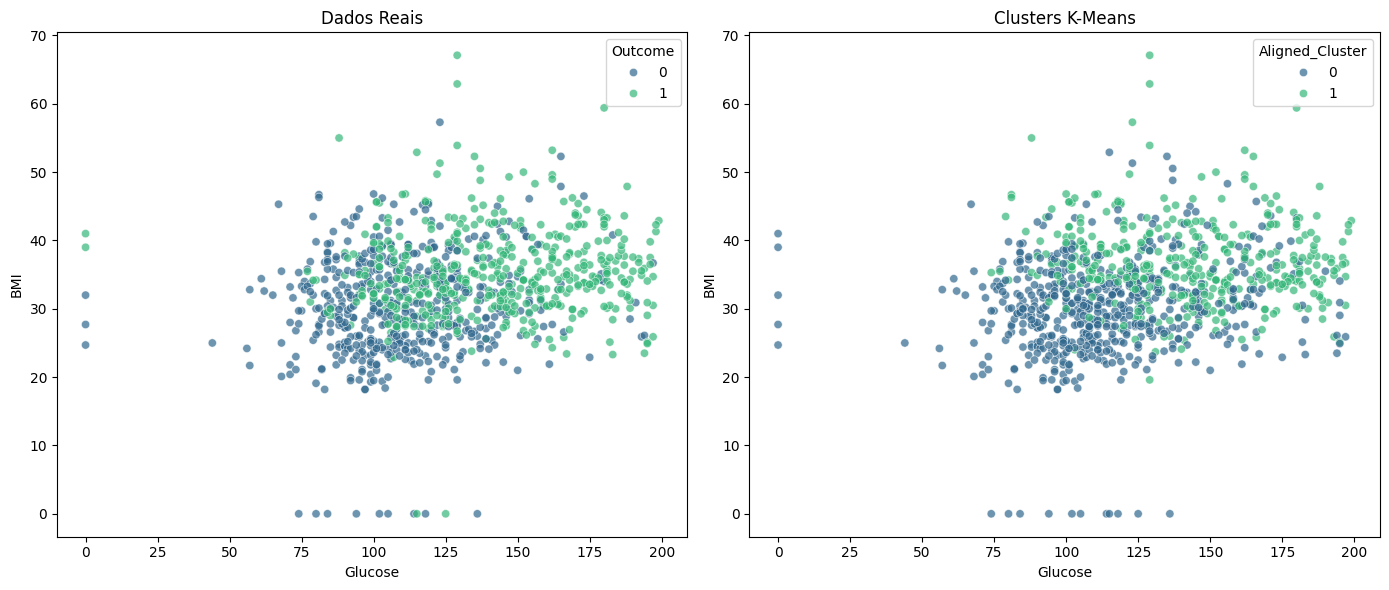

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizar o clustering em relação a duas features ('Glucose' e 'BMI') comparando com o y Outcome
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_balanceado, x='Glucose', y='BMI', hue='Outcome', palette='viridis', alpha=0.7)
plt.title('Dados Reais')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_balanceado, x='Glucose', y='BMI', hue='Aligned_Cluster', palette='viridis', alpha=0.7)
plt.title('Clusters K-Means')

plt.tight_layout()
plt.show()


A acurácia obtida pelo K-Means foi de aproximadamente 65%, indicando que os agrupamentos gerados apresentaram certa semelhança com os rótulos reais do dataset. Entretanto, como o K-Means é um algoritmo não supervisionado, ele realiza os agrupamentos com base apenas na similaridade matemática entre os dados, sem conhecimento prévio da variável alvo (Y).

Observou-se que o modelo agrupou mais registros na classe “1” (594 registros) do que na classe “0” (406 registros), mesmo após o balanceamento do dataset, que possuía 500 registros em cada classe. Isso demonstra que os grupos naturais encontrados pelo algoritmo não coincidem perfeitamente com as classes reais do problema.

